# Day-ahead solar and household demand forecasts

An evening schedule needs tomorrow's half-hourly gross PV generation and electricity use. This notebook compares supervised regression models with the same household's readings from one week earlier. See the [data audit and exploratory analysis](assignment_20_1.ipynb) for interval definitions and cleaning.

## Data availability and evaluation design

Each scored day has 48 valid meter intervals and complete lag days two and seven calendar days earlier. The lag days and calendar features are available by 18:00 Sydney time on the day before delivery. All homes on a date stay together in each split. The 2010–11 period supplies three expanding training folds for the grid. The 2011–12 period selects the fitted model family. The 2012–13 period evaluates the frozen choices.

From the repository root, run `OMP_NUM_THREADS=4 OPENBLAS_NUM_THREADS=4 python src/run_capstone.py` to regenerate the report used below. The [source](../src/run_capstone.py) contains the feature construction, model fitting, exhaustive grid, and evaluation.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
report = json.loads((root / "results/full_implementation.json").read_text())
folds = pd.DataFrame(report["cross_validation"]["folds"])
display(folds)

,train_through,validation_start,validation_end,intervals
0,2010-10-04,2010-10-06,2011-01-02,1267200
1,2011-01-02,2011-01-03,2011-03-31,1267200
2,2011-03-31,2011-04-01,2011-06-30,1267200


## Inspect an example forecast input

The two-home sample makes the feature alignment easy to inspect. Here we construct the same features as the full run for one complete day. The target is shown alongside the first three feature rows for inspection only.

In [2]:
import sys
from datetime import date, timedelta

sys.path.insert(0, str(root / "src"))
from run_capstone import design, read_panel

homes, days, readings = read_panel(root / "data/sample/ausgrid_sample.csv")
lookup = {(home, day): index for index, (home, day) in enumerate(zip(homes, days))}
delivery = date(2012, 7, 15)
home = homes[0]
index = lookup[home, delivery.toordinal()]
week = lookup[home, (delivery - timedelta(days=7)).toordinal()]
two_days = lookup[home, (delivery - timedelta(days=2)).toordinal()]
example = design(days[[index]], readings[[week]], readings[[two_days]])[0]
display(pd.DataFrame({
    "Sydney slot": ["00:00", "00:30", "01:00"],
    "Weekly PV lag": example[:3, 0],
    "Two-day PV lag": example[:3, 2],
    "Observed PV": readings[index, :3, 0],
}).round(3))

,Sydney slot,Weekly PV lag,Two-day PV lag,Observed PV
0,00:00,0.0,0.0,0.0
1,00:30,0.0,0.0,0.0
2,01:00,0.0,0.0,0.0


## Compare regressors and search the grid

Ordinary least squares estimates an additive relationship. Ridge shrinks coefficients to manage correlated lag features. Histogram gradient boosting can capture nonlinear effects such as interactions between the hour and prior PV. It fits a reproducible sample of up to 240,000 intervals per target in each training window.

RMSE weights large misses more heavily. We divide each target's RMSE by its persistence RMSE and average the two ratios to give solar and load equal influence. MAE measures the typical magnitude of an error in the original units. A ratio below one favors the model over persistence on the composite metric.

In [3]:
trials = pd.DataFrame(report["cross_validation"]["trials"])
display(trials.drop(columns="fold_scores").round(4))
fold_scores = pd.DataFrame([
    {"model": trial["method"], "fold": i, **score}
    for trial in report["cross_validation"]["trials"] if trial["selected_within_model"]
    for i, score in enumerate(trial["fold_scores"], start=1)
])
display(fold_scores.round(4))

,method,parameters,mean_normalized_rmse,selected_within_model
0,linear_regression,{},0.8188,True
1,ridge,{'alpha': 10.0},0.8189,False
2,ridge,{'alpha': 1000.0},0.8181,True
3,gradient_boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 15}",0.8256,True
4,gradient_boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 31}",0.8358,False
5,gradient_boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.8414,False
6,gradient_boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.8491,False


,model,fold,solar_rmse,load_rmse,normalized_rmse
0,linear_regression,1,0.1631,0.3294,0.8280
1,linear_regression,2,0.1413,0.3975,0.8269
2,linear_regression,3,0.1120,0.3927,0.8016
3,ridge,1,0.1626,0.3287,0.8257
4,ridge,2,0.1412,0.3975,0.8263
5,ridge,3,0.1123,0.3927,0.8024
6,gradient_boosting,1,0.1656,0.3255,0.8294
7,gradient_boosting,2,0.1534,0.3858,0.8521
8,gradient_boosting,3,0.1119,0.3873,0.7953


## Validation and held-out errors

The validation year selects the family after grid search. The held-out tables use kWh per half-hour. The 06:00–18:00 slice is a fixed clock window for examining solar performance. The tariff peak slice covers weekdays from 16:00 to 21:00 and is directly relevant to the dispatch decision.

In [4]:
rows = [
    {"split": split, "model": model, "window": window, "target": target, **scores}
    for split in ("validation", "test")
    for model, windows in report[split]["forecast"].items()
    for window, targets in windows.items() if targets is not None
    for target, scores in targets.items()
]
scores = pd.DataFrame(rows)
display(scores.query("window == 'all'").round(4))
display(scores.query("split == 'test' and window != 'all'").pivot(
    index=["window", "model"], columns="target", values="rmse"
).round(4))
print("Selected model:", report["selected_ml_model"].replace("_", " "))

,split,model,window,target,mae,rmse
0,validation,weekly_persistence,all,solar,0.0633,0.1605
1,validation,weekly_persistence,all,load,0.2255,0.4419
6,validation,linear_regression,all,solar,0.0601,0.1345
7,validation,linear_regression,all,load,0.2136,0.3618
12,validation,ridge,all,solar,0.0598,0.1345
13,validation,ridge,all,load,0.2137,0.3618
18,validation,gradient_boosting,all,solar,0.0569,0.1345
19,validation,gradient_boosting,all,load,0.2065,0.3550
24,test,weekly_persistence,all,solar,0.0591,0.1528
25,test,weekly_persistence,all,load,0.2254,0.4476


target                                   load   solar
window             model                             
06:00–18:00_sydney gradient_boosting   0.3631  0.1825
                   linear_regression   0.3707  0.1803
                   ridge               0.3706  0.1802
                   weekly_persistence  0.4559  0.2156
tariff_peak        gradient_boosting   0.4178  0.0770
                   linear_regression   0.4235  0.0794
                   ridge               0.4235  0.0793
                   weekly_persistence  0.5264  0.0925

Selected model: gradient boosting


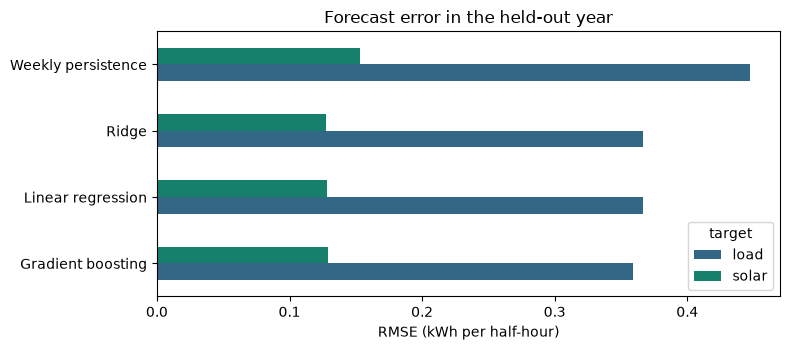

In [5]:
test_scores = scores.query("split == 'test' and window == 'all'")
chart = test_scores.pivot(index="model", columns="target", values="rmse")
chart.index = chart.index.str.replace("_", " ").str.capitalize()
ax = chart.plot.barh(figsize=(8, 3.6), color=["#326785", "#17806d"])
ax.set(xlabel="RMSE (kWh per half-hour)", ylabel="", title="Forecast error in the held-out year")
plt.tight_layout()
plt.show()

## Interpreting the forecasts

A model can improve RMSE while worsening MAE because it trades many small errors against fewer large ones. A forecast improvement also does not translate directly into a lower bill. The [dispatch evaluation](03_battery_dispatch.ipynb) measures that decision outcome under an explicit tariff and battery scenario.

Gradient boosting was selected on validation. On the held-out year, it lowered both target MAEs and RMSEs relative to the weekly benchmark. Ridge had the lowest solar RMSE, while gradient boosting had the lowest household demand RMSE.